<a href="https://colab.research.google.com/github/Valeria1100/Confiabilidad-y-planeaci-n-de-capacidad-de-un-servicio-de-inferencia-de-IA./blob/main/Punto_D.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Punto D parcial Fonseca

**D1.** Con las clases de tamaño definidas por t1, t2, construya la distribución conjunta
empírica de (clase de tamaño, cache_hit). Obtenga marginales y condicionales, y determine –con
evidencia cuantitativa e intervalos– si las dos variables son independientes. Figura 4 (mapa de
calor).

In [26]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Parámetros personalizados del grupo
S = 4063981172

t1 = 80 + 10 * (S % 5)
t2 = 400 + 25 * (S % 5)

# Nivel de confianza del 99%
confianza = 0.99
alpha = 1 - confianza

print("t1:", t1, "KB")
print("t2:", t2, "KB")
print("Nivel de confianza:", confianza)

t1: 100 KB
t2: 450 KB
Nivel de confianza: 0.99


In [27]:
# Buscamos los DataFrames que ya existen en el notebook
dataframes = {}

for nombre, objeto in globals().copy().items():

    if isinstance(objeto, pd.DataFrame):
        if 'tam_kb' in objeto.columns and 'cache_hit' in objeto.columns:
            dataframes[nombre] = objeto

# Revisamos si encontramos algún DataFrame válido
if len(dataframes) == 0:
    raise ValueError("No se encontró un DataFrame con tam_kb y cache_hit.")

# Damos prioridad al DataFrame del régimen estable o al limpio
def prioridad(nombre):
    nombre = nombre.lower()
    if 'estable' in nombre or 'regimen' in nombre:
        return 3
    elif 'limpio' in nombre or 'clean' in nombre:
        return 2
    else:
        return 1

nombre_datos = max(dataframes, key=prioridad)

# Utilizamos el DataFrame encontrado
df_d1 = dataframes[nombre_datos].copy()

print("DataFrame seleccionado:", nombre_datos)
print("Total de registros:", len(df_d1))
print("Columnas utilizadas:")
print(df_d1[['tam_kb', 'cache_hit']].head())

DataFrame seleccionado: df
Total de registros: 32472
Columnas utilizadas:
   tam_kb  cache_hit
0  108.47          0
1  629.91          0
2  179.72          0
3  429.34          0
4  229.65          0


In [28]:
# Clasificamos las solicitudes según su tamaño
df_d1['clase_tam'] = pd.cut(
    df_d1['tam_kb'],
    bins=[-np.inf, t1, t2, np.inf],
    labels=['Pequeña', 'Mediana', 'Grande'],
    right=False
)

# Revisamos la cantidad de solicitudes por categoría
print("Cantidad de solicitudes por clase:")
print(df_d1['clase_tam'].value_counts().sort_index())

# Revisamos si existen datos sin clasificar
print("\nDatos sin clasificar:")
print(df_d1['clase_tam'].isna().sum())

Cantidad de solicitudes por clase:
clase_tam
Pequeña     6496
Mediana    22332
Grande      3644
Name: count, dtype: int64

Datos sin clasificar:
0


In [29]:
# Construimos la tabla de frecuencias conjuntas
tabla_conjunta = pd.crosstab(
    df_d1['clase_tam'],
    df_d1['cache_hit']
)

# Organizamos las filas y columnas
tabla_conjunta = tabla_conjunta.reindex(
    index=['Pequeña', 'Mediana', 'Grande'],
    columns=[0, 1],
    fill_value=0
)

# Calculamos las probabilidades conjuntas
dist_conjunta = tabla_conjunta / tabla_conjunta.values.sum()

print("Frecuencias conjuntas:")
display(tabla_conjunta)
print("Probabilidades conjuntas:")
display(dist_conjunta.round(5))


# Calculamos las probabilidades marginales

marginal_clase = dist_conjunta.sum(axis=1)
marginal_cache = dist_conjunta.sum(axis=0)

print("Probabilidades marginales de tamaño:")
display(marginal_clase.round(5))
print("Probabilidades marginales de cache_hit:")
display(marginal_cache.round(5))

Frecuencias conjuntas:


cache_hit,0,1
clase_tam,,
Pequeña,3045,3451
Mediana,15086,7246
Grande,2975,669


Probabilidades conjuntas:


cache_hit,0,1
clase_tam,,
Pequeña,0.09377,0.10628
Mediana,0.46458,0.22315
Grande,0.09162,0.02060


Probabilidades marginales de tamaño:


,0
clase_tam,
Pequeña,0.20005
Mediana,0.68773
Grande,0.11222


Probabilidades marginales de cache_hit:


,0
cache_hit,
0,0.64998
1,0.35002


In [30]:
# Calculamos P(cache_hit | clase de tamaño)
condicional_cache = tabla_conjunta.div(
    tabla_conjunta.sum(axis=1),
    axis=0
)

print("Probabilidad de cache_hit según la clase:")
display(condicional_cache.round(5))


# Calculamos P(clase de tamaño | cache_hit)
condicional_clase = tabla_conjunta.div(
    tabla_conjunta.sum(axis=0),
    axis=1
)

print("Probabilidad de clase según cache_hit:")
display(condicional_clase.round(5))

Probabilidad de cache_hit según la clase:


cache_hit,0,1
clase_tam,,
Pequeña,0.46875,0.53125
Mediana,0.67553,0.32447
Grande,0.81641,0.18359


Probabilidad de clase según cache_hit:


cache_hit,0,1
clase_tam,,
Pequeña,0.14427,0.30362
Mediana,0.71477,0.63752
Grande,0.14096,0.05886


In [31]:
# Calculamos intervalos de confianza para cada clase
resultados_ic = []
for clase in ['Pequeña', 'Mediana', 'Grande']:

    # Seleccionamos las solicitudes de la clase
    datos = df_d1[df_d1['clase_tam'] == clase]

    # Contamos el total y los aciertos de caché
    n = len(datos)
    x = (datos['cache_hit'] == 1).sum()

    if n == 0:
        continue

    # Proporción observada
    p = x / n

    # Límite inferior del intervalo
    if x == 0:
        inferior = 0
    else:
        inferior = stats.beta.ppf(
            alpha / 2,
            x,
            n - x + 1
        )

    # Límite superior del intervalo
    if x == n:
        superior = 1
    else:
        superior = stats.beta.ppf(
            1 - alpha / 2,
            x + 1,
            n - x
        )

    # Guardamos los resultados
    resultados_ic.append({
        'Clase': clase,
        'Total': n,
        'Cache hit': x,
        'Proporción': p,
        'IC inferior': inferior,
        'IC superior': superior
    })

# Creamos la tabla final
tabla_ic = pd.DataFrame(resultados_ic)

print("Intervalos de confianza del 99 %:")
display(tabla_ic.round(5))

Intervalos de confianza del 99 %:


,Clase,Total,Cache hit,Proporción,IC inferior,IC superior
0,Pequeña,6496,3451,0.53125,0.51521,0.54725
1,Mediana,22332,7246,0.32447,0.31641,0.33260
2,Grande,3644,669,0.18359,0.16736,0.20066


In [32]:
# Realizamos la prueba Chi-cuadrado de independencia
chi2, p_valor, grados_libertad, esperadas = stats.chi2_contingency(
    tabla_conjunta,
    correction=False
)

# Calculamos el coeficiente V de Cramér
n = tabla_conjunta.values.sum()

v_cramer = np.sqrt(
    chi2 / (
        n * min(
            tabla_conjunta.shape[0] - 1,
            tabla_conjunta.shape[1] - 1
        )
    )
)

# Mostramos los resultados
print("RESULTADOS DE INDEPENDENCIA")
print("Chi-cuadrado:", round(chi2, 4))
print("Grados de libertad:", grados_libertad)
print("Valor p:", p_valor)
print("V de Cramér:", round(v_cramer, 5))

# Mostramos las frecuencias esperadas
print("\nFrecuencias esperadas:")
display(pd.DataFrame(
    esperadas,
    index=tabla_conjunta.index,
    columns=tabla_conjunta.columns
).round(2))

# Comparamos el valor p con el nivel de significancia
if p_valor < alpha:

    print("\nSe rechaza H0.")
    print("Existe evidencia estadística de asociación entre las variables.")

else:

    print("\nNo se rechaza H0.")
    print("No hay evidencia suficiente para descartar la independencia.")

# Revisamos las frecuencias esperadas para comprobar
# que se pueda utilizar la aproximación Chi-cuadrado
if (esperadas < 5).any():

    print("\nAdvertencia: hay frecuencias esperadas menores que 5.")

else:

    print("\nTodas las frecuencias esperadas son mayores o iguales a 5.")

RESULTADOS DE INDEPENDENCIA
Chi-cuadrado: 1445.5527
Grados de libertad: 2
Valor p: 0.0
V de Cramér: 0.21099

Frecuencias esperadas:


cache_hit,0,1
clase_tam,,
Pequeña,4222.24,2273.76
Mediana,14515.25,7816.75
Grande,2368.51,1275.49



Se rechaza H0.
Existe evidencia estadística de asociación entre las variables.

Todas las frecuencias esperadas son mayores o iguales a 5.


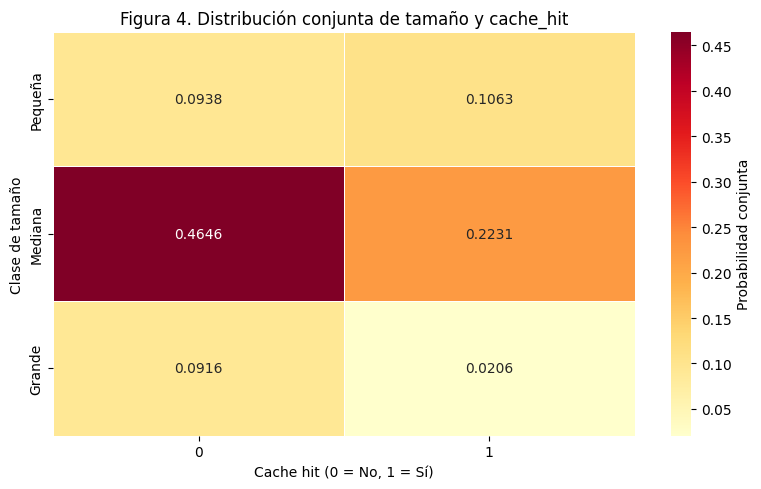

In [33]:
plt.figure(figsize=(8, 5))
sns.heatmap(
    dist_conjunta,
    annot=True,
    fmt='.4f',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'Probabilidad conjunta'}
)

plt.title('Figura 4. Distribución conjunta de tamaño y cache_hit')
plt.xlabel('Cache hit (0 = No, 1 = Sí)')
plt.ylabel('Clase de tamaño')
plt.tight_layout()
plt.show()

**D2**. Estime E[G | clase, no caché] y E[G | tam_kb] de forma no paramétrica. Verifique
numéricamente la ley de la esperanza total y la de la varianza total para G, y cuantifique qué
fracción de Var(G) queda explicada por la clase de tamaño.


In [35]:
# Creamos una copia de los datos que utilizamos en D1
if 'df_d1' in globals():
    datos_d2 = df_d1.copy()
elif 'datos_d1' in globals():
    datos_d2 = datos_d1.copy()
else:
    raise NameError("No se encontraron los datos de D1.")


# Revisamos el nombre de la columna de clase
if 'clase_tam' in datos_d2.columns:

    datos_d2 = datos_d2.rename(
        columns={'clase_tam': 'clase_tamano'}
    )


# Revisamos que tengamos las columnas necesarias
print("Columnas utilizadas en D2:")
print(datos_d2.columns.tolist())
print("\nTotal de solicitudes:")
print(len(datos_d2))

Columnas utilizadas en D2:
['id_solicitud', 't_llegada_s', 'tam_kb', 'cache_hit', 'version', 'red_ms', 'gpu_ms', 'latencia_ms', 'intentos', 'exito', 'clase_tamano']

Total de solicitudes:
32472


In [36]:
# Revisamos los valores faltantes de gpu_ms
print("Valores faltantes de GPU:")
print(datos_d2['gpu_ms'].isna().sum())


# Contamos los faltantes de solicitudes con caché
faltantes_cache = (
    (datos_d2['cache_hit'] == 1) &
    (datos_d2['gpu_ms'].isna())
).sum()


# Completamos con cero porque estas solicitudes no utilizaron GPU
datos_d2.loc[
    (datos_d2['cache_hit'] == 1) &
    (datos_d2['gpu_ms'].isna()),
    'gpu_ms'
] = 0


# Eliminamos los registros donde no conocemos el tiempo de GPU
datos_d2 = datos_d2.dropna(
    subset=['gpu_ms', 'tam_kb', 'clase_tamano', 'cache_hit']
).copy()


# Mostramos los resultados de la preparación
print("\nFaltantes de solicitudes con caché corregidos:", faltantes_cache)
print("Solicitudes disponibles para D2:", len(datos_d2))
print("Valores faltantes restantes:")
print(datos_d2[['gpu_ms', 'tam_kb']].isna().sum())

Valores faltantes de GPU:
32

Faltantes de solicitudes con caché corregidos: 14
Solicitudes disponibles para D2: 32454
Valores faltantes restantes:
gpu_ms    0
tam_kb    0
dtype: int64


In [37]:
# Separamos las solicitudes que no utilizaron caché
datos_no_cache = datos_d2[
    datos_d2['cache_hit'] == 0
].copy()

# Mostramos la cantidad de solicitudes sin caché
print("Solicitudes sin caché:", len(datos_no_cache))

# Revisamos los primeros tiempos de GPU
print("\nPrimeros tiempos de GPU:")
display(datos_no_cache[['tam_kb', 'gpu_ms', 'clase_tamano']].head())

Solicitudes sin caché: 21088

Primeros tiempos de GPU:


,tam_kb,gpu_ms,clase_tamano
0,108.47,8.37,Mediana
1,629.91,149.39,Grande
2,179.72,49.68,Mediana
3,429.34,66.91,Mediana
4,229.65,33.09,Mediana


In [38]:
# Agrupamos las solicitudes según su clase de tamaño
esperanza_clase = datos_no_cache.groupby(
    'clase_tamano',
    observed=False
)['gpu_ms'].agg(
    ['count', 'mean', 'std']
)


# Cambiamos los nombres de las columnas
esperanza_clase.columns = [
    'Cantidad',
    'Promedio_GPU_ms',
    'Desviacion_GPU_ms'
]


# Mostramos los resultados
print("Esperanza del tiempo de GPU según la clase:")
display(esperanza_clase.round(4))

Esperanza del tiempo de GPU según la clase:


,Cantidad,Promedio_GPU_ms,Desviacion_GPU_ms
clase_tamano,,,
Pequeña,3043,22.1022,13.4179
Mediana,15074,46.0343,30.7259
Grande,2971,98.6529,62.5685


In [39]:
# Dividimos los tamaños en 20 grupos según sus cuantiles
datos_d2['grupo_tamano'] = pd.qcut(
    datos_d2['tam_kb'],
    q=20,
    duplicates='drop'
)


# Calculamos los promedios de cada grupo
tabla_tamano = datos_d2.groupby(
    'grupo_tamano',
    observed=True
).agg(
    cantidad=('gpu_ms', 'count'),
    tamano_promedio=('tam_kb', 'mean'),
    tiempo_promedio=('gpu_ms', 'mean')
)


# Mostramos la tabla de resultados
print("Esperanza de GPU según el tamaño:")
display(tabla_tamano.round(4))

Esperanza de GPU según el tamaño:


,cantidad,tamano_promedio,tiempo_promedio
grupo_tamano,,,
"(0.159, 43.7]",1624,27.9904,8.0581
"(43.7, 65.343]",1622,54.6959,9.6784
"(65.343, 83.018]",1622,74.3807,11.4356
"(83.018, 99.938]",1623,91.5988,12.2349
"(99.938, 116.16]",1624,108.1039,18.8465
"(116.16, 132.94]",1622,124.4035,20.9516
"(132.94, 148.55]",1624,140.8729,22.2957
"(148.55, 165.08]",1622,157.0366,23.3731
"(165.08, 182.788]",1621,174.0267,24.5529


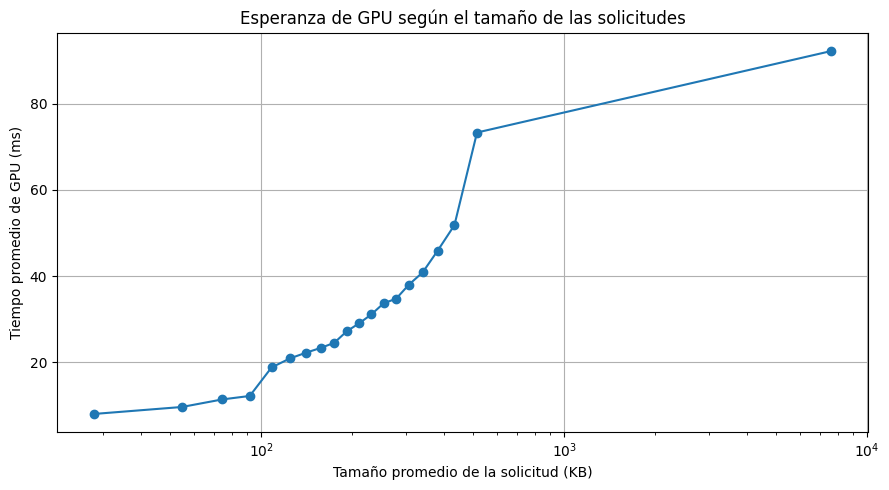

In [40]:
plt.figure(figsize=(9, 5))
plt.plot(
    tabla_tamano['tamano_promedio'],
    tabla_tamano['tiempo_promedio'],
    marker='o'
)

plt.title('Esperanza de GPU según el tamaño de las solicitudes')
plt.xlabel('Tamaño promedio de la solicitud (KB)')
plt.ylabel('Tiempo promedio de GPU (ms)')
plt.xscale('log')
plt.grid()
plt.tight_layout()
plt.show()

In [41]:
# Calculamos el promedio general de GPU
esperanza_general = datos_d2['gpu_ms'].mean()

# Agrupamos los datos según su clase
resumen_clases = datos_d2.groupby(
    'clase_tamano',
    observed=False
).agg(
    cantidad=('gpu_ms', 'count'),
    promedio=('gpu_ms', 'mean')
)

# Calculamos la probabilidad de cada clase
resumen_clases['probabilidad'] = (
    resumen_clases['cantidad'] / len(datos_d2)
)

# Calculamos la esperanza utilizando las clases
esperanza_por_clases = (
    resumen_clases['probabilidad'] *
    resumen_clases['promedio']
).sum()

# Mostramos los resultados
print("LEY DE LA ESPERANZA TOTAL")
print("Esperanza general:", esperanza_general)
print("Esperanza por clases:", esperanza_por_clases)
print("Diferencia:",abs(esperanza_general - esperanza_por_clases))

# Verificamos si los resultados coinciden
if np.isclose(esperanza_general, esperanza_por_clases):
    print("\nSe cumple la ley de la esperanza total.")
else:
    print("\nNo se cumple la ley de la esperanza total.")

LEY DE LA ESPERANZA TOTAL
Esperanza general: 32.4852471189992
Esperanza por clases: 32.485247118999204
Diferencia: 7.105427357601002e-15

Se cumple la ley de la esperanza total.


In [42]:
# Calculamos la varianza dentro de cada clase
varianza_clases = datos_d2.groupby(
    'clase_tamano',
    observed=False
)['gpu_ms'].var(ddof=0)

# Agregamos las varianzas a nuestra tabla
resumen_clases['varianza'] = varianza_clases

# Calculamos la varianza total de GPU
varianza_general = datos_d2['gpu_ms'].var(ddof=0)

# Calculamos la varianza dentro de las clases
varianza_dentro = (
    resumen_clases['probabilidad'] *
    resumen_clases['varianza']
).sum()

# Calculamos la varianza entre las clases
varianza_entre = (
    resumen_clases['probabilidad'] *
    (resumen_clases['promedio'] - esperanza_general) ** 2
).sum()

# Sumamos los dos componentes
varianza_calculada = varianza_dentro + varianza_entre

# Mostramos los resultados
print("LEY DE LA VARIANZA TOTAL")
print("Varianza general:", varianza_general)
print("Varianza dentro de las clases:", varianza_dentro)
print("Varianza entre las clases:", varianza_entre)
print("Suma de las dos varianzas:", varianza_calculada)
print("Diferencia:",abs(varianza_general - varianza_calculada))

# Comprobamos la igualdad
if np.isclose(varianza_general, varianza_calculada):
    print("\nSe cumple la ley de la varianza total.")
else:
    print("\nNo se cumple la ley de la varianza total.")

LEY DE LA VARIANZA TOTAL
Varianza general: 1679.3625312861616
Varianza dentro de las clases: 1321.2384602405702
Varianza entre las clases: 358.1240710458117
Suma de las dos varianzas: 1679.362531286382
Diferencia: 2.2032509150449187e-10

Se cumple la ley de la varianza total.


**D3.** Ajuste un modelo lineal para E[G | tam_kb, no caché] por mínimos cuadrados,
planteando y resolviendo usted mismo el sistema matricial correspondiente (sin sklearn ni
statsmodels). Entregue intervalos de confianza para los coeficientes, analice los residuos y, si
encuentra una violación de supuestos, proponga y aplique una corrección fundamentada en la
estructura probabilística de los datos. Figura 5.

In [43]:
# Utilizamos los datos sin caché que trabajamos en D2
reg = datos_no_cache[['tam_kb', 'gpu_ms']].dropna().copy()

# Convertimos las variables a valores numéricos
x = reg['tam_kb'].to_numpy(dtype=float)
y = reg['gpu_ms'].to_numpy(dtype=float)

# Revisamos la cantidad de datos
print("Total de solicitudes no cacheadas:", len(reg))
print("\nPrimeros registros:")
display(reg.head())
print("\nTamaño mínimo:", x.min(), "KB")
print("Tamaño máximo:", x.max(), "KB")

Total de solicitudes no cacheadas: 21088

Primeros registros:


,tam_kb,gpu_ms
0,108.47,8.37
1,629.91,149.39
2,179.72,49.68
3,429.34,66.91
4,229.65,33.09



Tamaño mínimo: 0.16 KB
Tamaño máximo: 1020774.4 KB


In [44]:
# Construimos la matriz de diseño
X = np.column_stack((
    np.ones(len(x)),
    x
))

# Calculamos los dos lados del sistema matricial
XtX = X.T @ X
Xty = X.T @ y

# Mostramos las matrices obtenidas
print("Matriz X transpuesta por X:")
print(XtX)
print("\nVector X transpuesta por y:")
print(Xty)

Matriz X transpuesta por X:
[[2.10880000e+04 1.27854533e+07]
 [1.27854533e+07 3.18961520e+12]]

Vector X transpuesta por y:
[1.05427621e+06 9.17821652e+08]


In [45]:
# Resolvemos el sistema matricial de mínimos cuadrados
beta = np.linalg.solve(XtX, Xty)

# Separamos los coeficientes
beta0 = beta[0]
beta1 = beta[1]

# Calculamos los valores estimados por el modelo
ajustados = X @ beta

# Calculamos los residuos
residuos = y - ajustados

# Mostramos los resultados
print("RESULTADOS DEL MODELO LINEAL")
print("Intercepto beta0:", beta0)
print("Pendiente beta1:", beta1)
print("\nModelo obtenido:")
print("G estimado =", beta0, "+", beta1, "* tam_kb")

RESULTADOS DEL MODELO LINEAL
Intercepto beta0: 49.94103921913871
Pendiente beta1: 8.756630875076625e-05

Modelo obtenido:
G estimado = 49.94103921913871 + 8.756630875076625e-05 * tam_kb


In [46]:
# Calculamos las medidas de ajuste del modelo
n = len(y)
p = X.shape[1]
gl = n - p

# Suma de cuadrados de los residuos
sse = np.sum(residuos**2)

# Suma total de cuadrados
sst = np.sum((y - y.mean())**2)

# Calculamos R cuadrado
r2 = 1 - sse / sst

# Calculamos la varianza residual
s2 = sse / gl

# Desviación residual
desviacion_residual = np.sqrt(s2)

# Mostramos los resultados
print("EVALUACIÓN DEL MODELO")
print("R cuadrado:", r2)
print("Suma de cuadrados de residuos:", sse)
print("Desviación residual:", desviacion_residual)
print("Grados de libertad:", gl)

EVALUACIÓN DEL MODELO
R cuadrado: 0.0006769190100642808
Suma de cuadrados de residuos: 36018434.998345956
Desviación residual: 41.32999172271138
Grados de libertad: 21086


In [47]:
# Calculamos la matriz de covarianza clásica
cov_clasica = s2 * np.linalg.inv(XtX)

# Obtenemos los errores estándar de los coeficientes
se_clasicos = np.sqrt(np.diag(cov_clasica))

# Calculamos el valor crítico de la distribución t
tcrit = stats.t.ppf(0.995, gl)

# Calculamos los límites de los intervalos
limite_inferior = beta - tcrit * se_clasicos
limite_superior = beta + tcrit * se_clasicos

# Organizamos los resultados en una tabla
tabla_coeficientes = pd.DataFrame({
    'Coeficiente': beta,
    'Error estandar': se_clasicos,
    'IC inferior 99%': limite_inferior,
    'IC superior 99%': limite_superior
}, index=['Intercepto', 'Pendiente'])

# Mostramos los intervalos
print("INTERVALOS DE CONFIANZA DEL 99%")
display(tabla_coeficientes.round(6))

INTERVALOS DE CONFIANZA DEL 99%


,Coeficiente,Error estandar,IC inferior 99%,IC superior 99%
Intercepto,49.941039,0.284955,49.206978,50.675101
Pendiente,0.000088,0.000023,0.000028,0.000147


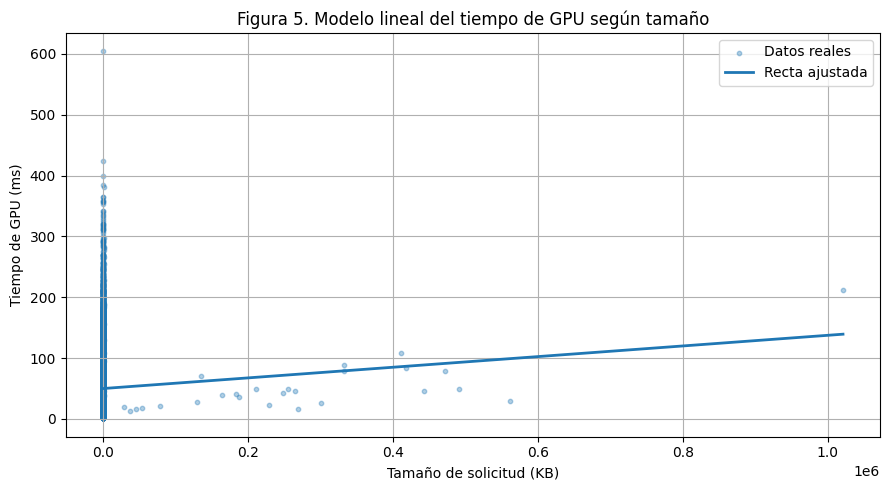

In [48]:
# Organizamos los datos de menor a mayor tamaño
orden = np.argsort(x)

# Creamos la figura del modelo lineal
plt.figure(figsize=(9, 5))

# Graficamos las observaciones reales
plt.scatter(
    x,
    y,
    s=10,
    alpha=0.35,
    label='Datos reales'
)

# Graficamos la recta obtenida por mínimos cuadrados
plt.plot(
    x[orden],
    ajustados[orden],
    label='Recta ajustada',
    linewidth=2
)

# Agregamos títulos y nombres de los ejes
plt.title('Figura 5. Modelo lineal del tiempo de GPU según tamaño')
plt.xlabel('Tamaño de solicitud (KB)')
plt.ylabel('Tiempo de GPU (ms)')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

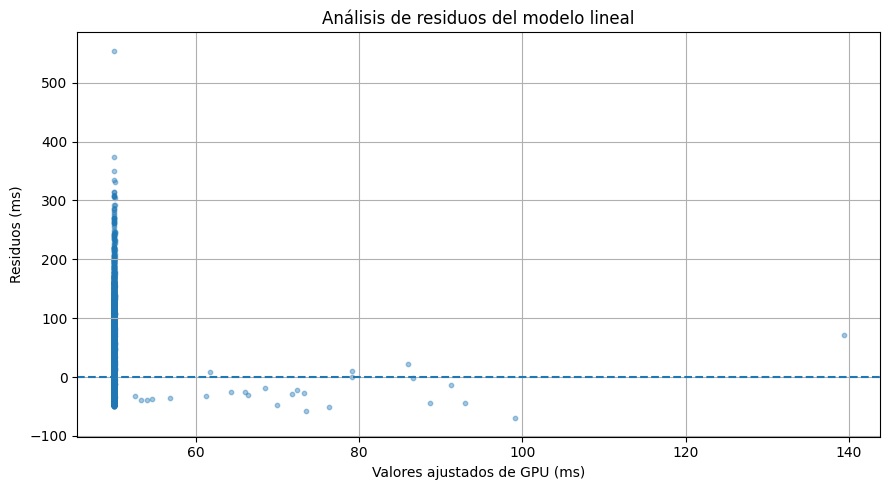

In [49]:
# Graficamos los residuos frente a los valores ajustados
plt.figure(figsize=(9, 5))
plt.scatter(
    ajustados,
    residuos,
    s=10,
    alpha=0.4
)

# Agregamos una línea horizontal en cero
plt.axhline(
    0,
    linestyle='--'
)

# Configuramos la gráfica
plt.title('Análisis de residuos del modelo lineal')
plt.xlabel('Valores ajustados de GPU (ms)')
plt.ylabel('Residuos (ms)')
plt.grid()
plt.tight_layout()
plt.show()

In [50]:
# Elevamos los residuos al cuadrado
u2 = residuos**2

# Construimos la regresión auxiliar
gamma = np.linalg.solve(
    XtX,
    X.T @ u2
)

# Calculamos los valores estimados de la regresión auxiliar
u2_ajustado = X @ gamma

# Calculamos las sumas de cuadrados
sse_aux = np.sum((u2 - u2_ajustado)**2)
sst_aux = np.sum((u2 - u2.mean())**2)

# Calculamos el R cuadrado auxiliar
r2_aux = 1 - sse_aux / sst_aux

# Estadístico de Breusch-Pagan
bp = n * r2_aux

# Calculamos el valor p
p_bp = stats.chi2.sf(bp, df=1)

# Mostramos los resultados
print("PRUEBA DE BREUSCH-PAGAN")
print("Estadístico LM:", bp)
print("Valor p:", p_bp)
print("Nivel de significancia:", 0.01)

# Tomamos la decisión
if p_bp < 0.01:
    print("\nSe rechaza H0.")
    print("Existe evidencia de heterocedasticidad.")
else:
    print("\nNo se rechaza H0.")
    print("No se encontró evidencia suficiente de heterocedasticidad.")

PRUEBA DE BREUSCH-PAGAN
Estadístico LM: 0.7531655659480165
Valor p: 0.38547584086982345
Nivel de significancia: 0.01

No se rechaza H0.
No se encontró evidencia suficiente de heterocedasticidad.


In [51]:
# Calculamos la inversa de la matriz XtX
XtX_inv = np.linalg.inv(XtX)

# Calculamos la matriz de proyección
H = X @ XtX_inv @ X.T

# Obtenemos los valores de la diagonal
h = np.diag(H)

# Calculamos el ajuste HC3 de los residuos
ajuste_hc3 = (residuos / (1 - h))**2

# Construimos la parte central de la matriz robusta
meat = X.T @ (X * ajuste_hc3[:, None])

# Calculamos la matriz de covarianza robusta
cov_hc3 = XtX_inv @ meat @ XtX_inv

# Calculamos los errores estándar robustos
se_hc3 = np.sqrt(np.diag(cov_hc3))

# Calculamos los intervalos robustos del 99%
inferior_hc3 = beta - tcrit * se_hc3
superior_hc3 = beta + tcrit * se_hc3

# Organizamos los resultados
tabla_hc3 = pd.DataFrame({
    'Coeficiente': beta,
    'Error estandar HC3': se_hc3,
    'IC inferior 99%': inferior_hc3,
    'IC superior 99%': superior_hc3
}, index=['Intercepto', 'Pendiente'])

# Mostramos los resultados corregidos
print("INTERVALOS DE CONFIANZA ROBUSTOS HC3")
display(tabla_hc3.round(6))

INTERVALOS DE CONFIANZA ROBUSTOS HC3


,Coeficiente,Error estandar HC3,IC inferior 99%,IC superior 99%
Intercepto,49.941039,0.285135,49.206513,50.675565
Pendiente,0.000088,0.000040,-0.000014,0.000190


**D4**. Calcule la covarianza y la correlación entre tam_kb y gpu_ms (no cacheadas) e interprete su relación con los resultados de D2 y D3.

In [52]:
datos_d4 = reg[['tam_kb', 'gpu_ms']].dropna().copy()

# Obtenemos las variables que vamos a analizar
tamano = datos_d4['tam_kb']
tiempo_gpu = datos_d4['gpu_ms']

# Mostramos la cantidad de registros
print("Total de solicitudes no cacheadas:", len(datos_d4))
print("\nPrimeros registros:")
display(datos_d4.head())

Total de solicitudes no cacheadas: 21088

Primeros registros:


,tam_kb,gpu_ms
0,108.47,8.37
1,629.91,149.39
2,179.72,49.68
3,429.34,66.91
4,229.65,33.09


In [53]:
# Calculamos la covarianza entre el tamaño y el tiempo de GPU
covarianza = tamano.cov(tiempo_gpu)

# Mostramos el resultado

print("COVARIANZA")
print("Covarianza entre tam_kb y gpu_ms:", covarianza)

COVARIANZA
Covarianza entre tam_kb y gpu_ms: 13213.0716551912


In [54]:
# Calculamos la correlación de Pearson
correlacion = tamano.corr(tiempo_gpu)

# Mostramos el resultado

print("CORRELACIÓN DE PEARSON")
print("Correlación entre tam_kb y gpu_ms:", correlacion)

CORRELACIÓN DE PEARSON
Correlación entre tam_kb y gpu_ms: 0.026017667267918997


In [55]:
# Interpretamos el signo de la covarianza

print("INTERPRETACIÓN DE LOS RESULTADOS")

if covarianza > 0:
    print("La covarianza es positiva.")
    print("Las variables tienden a aumentar conjuntamente.")
elif covarianza < 0:
    print("La covarianza es negativa.")
    print("Las variables tienden a moverse en sentidos opuestos.")
else:
    print("La covarianza es cero.")


# Interpretamos la intensidad de la correlación

valor_corr = abs(correlacion)

if valor_corr < 0.20:
    intensidad = "muy débil"
elif valor_corr < 0.40:
    intensidad = "débil"
elif valor_corr < 0.60:
    intensidad = "moderada"
elif valor_corr < 0.80:
    intensidad = "fuerte"
else:

    intensidad = "muy fuerte"

print("\nCorrelación:", correlacion)
print("Intensidad de la relación:", intensidad)

if correlacion > 0:
    print("La relación lineal es positiva.")
elif correlacion < 0:
    print("La relación lineal es negativa.")
else:
    print("No existe relación lineal según Pearson.")

INTERPRETACIÓN DE LOS RESULTADOS
La covarianza es positiva.
Las variables tienden a aumentar conjuntamente.

Correlación: 0.026017667267918997
Intensidad de la relación: muy débil
La relación lineal es positiva.


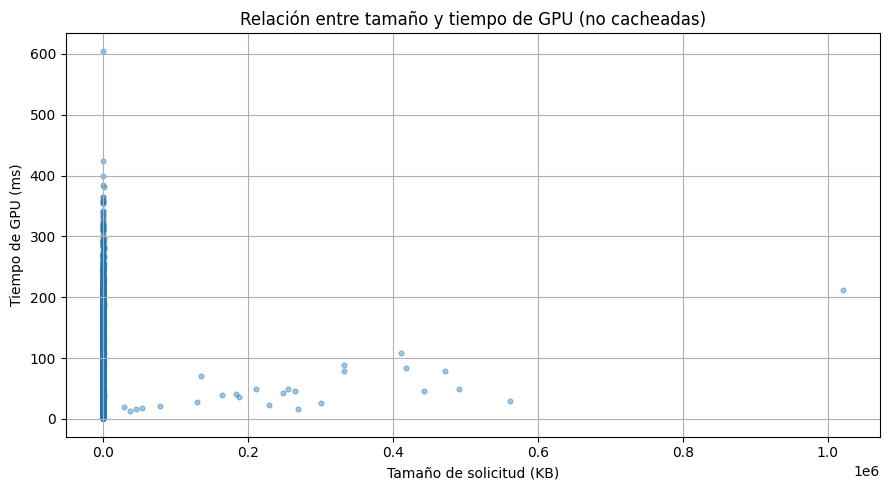

In [56]:
# Graficamos la relación entre tamaño y tiempo de GPU
plt.figure(figsize=(9, 5))
plt.scatter(
    tamano,
    tiempo_gpu,
    alpha=0.4,
    s=12
)

# Agregamos los títulos y nombres de los ejes
plt.title('Relación entre tamaño y tiempo de GPU (no cacheadas)')
plt.xlabel('Tamaño de solicitud (KB)')
plt.ylabel('Tiempo de GPU (ms)')
plt.grid()
plt.tight_layout()
plt.show()